### Die Siedler – Lösung Schritt für Schritt

*42. Bundeswettbewerb Informatik (2023/2024), 2. Runde, Aufgabe 3*

In einem fernen Land wütete vor einiger Zeit eine verheerende ansteckende Epidemie. Das Land ächzt heute noch unter den Folgen.
Es stellt sich die Frage, wie solche Epidemien in Zukunft verhindert werden können. Es ist bekannt, dass ein Zusammenhang zwischen
der räumlichen Nähe von Ortschaften und der Ausbreitung von Krankheiten besteht.

Es gibt größere Gebiete in dem Land, die bisher nicht besiedelt wurden, aber wertvolle Bodenschätze und fruchtbares Ackerland
enthalten. Die Regierung des Landes möchte die Besiedlung durch Ortschaften so organisieren, dass jeweils zwei Ortschaften
**mindestens 10 km** voneinander entfernt sind. Wenn der Abstand zwischen zwei Ortschaften **mindestens 20 km** beträgt, dann ist
garantiert, dass das Auftreten einer Krankheit in einer Ortschaft nicht auf die andere übergreift. Außerdem steht genügend Geld zur
Verfügung, um ein **Gesundheitszentrum** zu bauen: Alle Ortschaften in einer Entfernung **bis zu 85 km** vom Gesundheitszentrum sind
dann vollständig geschützt. Das heißt, die Krankheit bricht weder aus noch wird sie weitergegeben.

#### Aufgabe

Gegeben ist ein Gebiet in Form eines Polygons. Für dieses Gebiet sollen die Positionen möglichst vieler Ortschaften und eines
Gesundheitszentrums so geplant werden, dass die Weitergabe von Krankheiten zwischen den Ortschaften nicht möglich ist. Schreibe ein
Programm, das einen entsprechenden Besiedlungsplan erstellt.

Wende dein Programm mindestens auf alle Beispiele an, die du auf den BWINF-Webseiten findest, und dokumentiere die Ergebnisse.

#### Beispieldaten

In `beispieldaten/` liegen `siedler1.txt` bis `siedler5.txt`. Die erste Zeile ist die Zahl der Ecken des Polygons, danach folgt
pro Zeile eine Ecke (x- und y-Koordinate in km, der Reihe nach um das Gebiet herum).

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**

- **Greedy-Verfahren:** Man setzt nacheinander jeweils die nächste Ortschaft an eine „gute“ Stelle und nimmt nichts zurück. Eine
  gute Stelle ist hier eine, die so nah an den bisherigen Ortschaften liegt, wie die Regeln erlauben, damit möglichst wenig Platz
  verschenkt wird.
- **Kandidaten statt Suche im Gebiet:** Das Gebiet hat unendlich viele Punkte. Die Ortschaften, die „so eng wie möglich“ liegen,
  stehen aber immer auf **Schnittpunkten von Kreisen** (um andere Ortschaften) und mit dem **Rand**. Nur diese Punkte probieren wir.
- **Prioritätswarteschlange:** Die Kandidaten kommen in eine Warteschlange, die immer den wichtigsten zuerst herausgibt.
- **Punkt-in-Polygon-Test:** Liegt ein Punkt im Gebiet? Ein Strahl vom Punkt aus kreuzt den Rand bei „innen“ ungerade oft.
- **Suche nach den Startwerten:** Das Greedy-Verfahren hängt von seinem Start ab. Wir probieren viele Starts zufällig aus und
  verbessern den besten durch kleine zufällige Änderungen (**Zufallssuche**, **lokale Verbesserung**).
- **Obere Schranke:** Eine einfache Flächenüberlegung sagt, wie viele Ortschaften höchstens möglich sind. Damit bekommen wir ein
  Gefühl, wie gut ein Ergebnis ist.

**Nützliche Bibliotheken und Funktionen**

- `math.hypot`, `math.sqrt`, `math.cos`, `math.sin` für Abstände und Kreisschnitte
- `heapq.heappush` und `heapq.heappop` für die Prioritätswarteschlange (gibt immer das kleinste Element zuerst heraus; Tupel
  werden von links nach rechts verglichen)
- `random.Random(zahl)` für Zufallszahlen, die bei jedem Lauf gleich sind (damit die Ergebnisse im Notebook reproduzierbar sind),
  mit `uniform` und `gauss`
- `matplotlib.pyplot` für die Zeichnung der Pläne (optional)

## Schritt 1: Daten einlesen und eine obere Schranke

Zuerst lesen wir die Polygone ein. Zur Einordnung der späteren Ergebnisse rechnen wir noch eine **obere Schranke** aus. Im
besten Fall liegen die Ortschaften wie die Mittelpunkte von regelmäßigen Sechsecken (dichteste Packung). Eine Ortschaft braucht
dann mindestens die Fläche eines Sechsecks mit dem Innenkreisradius 5 km, das ist `wurzel(3)/2 * 10 * 10` km². Weil die Ortschaften
auch am Rand stehen dürfen, ist die nutzbare Fläche höchstens `Fläche + Umfang * 5`. Es passen also weniger als

`(Fläche + Umfang * 5) / (wurzel(3)/2 * 100)`

Ortschaften in das Gebiet. Die Fläche des Polygons bekommen wir mit der **Gaußschen Trapezformel**: Für jede Kante `(x1,y1) → (x2,y2)`
addiert man `x1*y2 - x2*y1`, am Ende nimmt man den halben Betrag der Summe.

In [ ]:
import math


def lies_polygon(dateiname):
    datei = open(dateiname)
    zeilen = datei.read().split()
    datei.close()
    n = int(zeilen[0])
    polygon = []
    for i in range(n):
        polygon.append((float(zeilen[1 + 2 * i]), float(zeilen[2 + 2 * i])))
    return polygon


def abstand(a, b):
    return math.hypot(a[0] - b[0], a[1] - b[1])


def flaeche_und_umfang(polygon):
    n = len(polygon)
    summe = 0.0
    umfang = 0.0
    for i in range(n):
        p = polygon[i]
        q = polygon[(i + 1) % n]
        summe += p[0] * q[1] - q[0] * p[1]
        umfang += abstand(p, q)
    return abs(summe) / 2, umfang


def obere_schranke(polygon):
    flaeche, umfang = flaeche_und_umfang(polygon)
    return (flaeche + umfang * 5) / (math.sqrt(3) / 2 * 100)


gebiete = {}
for nr in range(1, 6):
    gebiete[nr] = lies_polygon('beispieldaten/siedler' + str(nr) + '.txt')
    flaeche, umfang = flaeche_und_umfang(gebiete[nr])
    print('siedler' + str(nr) + ':', len(gebiete[nr]), 'Ecken, Fläche', round(flaeche), 'km², Umfang', round(umfang), 'km,',
          'weniger als', round(obere_schranke(gebiete[nr]), 1), 'Ortschaften')

siedler1: 4 Ecken, Fläche 16250 km², Umfang 788 km, weniger als 233.2 Ortschaften
siedler2: 20 Ecken, Fläche 5762 km², Umfang 1639 km, weniger als 161.1 Ortschaften
siedler3: 4 Ecken, Fläche 22500 km², Umfang 600 km, weniger als 294.4 Ortschaften
siedler4: 22 Ecken, Fläche 15600 km², Umfang 1904 km, weniger als 290.1 Ortschaften
siedler5: 16 Ecken, Fläche 16460 km², Umfang 1080 km, weniger als 252.4 Ortschaften


## Schritt 2: Liegt ein Punkt im Gebiet?

Ein Punkt gehört zum Gebiet, wenn er **im Inneren oder auf dem Rand** liegt (Ortschaften dürfen auf dem Rand stehen). Für das
Innere zählen wir, wie oft ein waagerechter Strahl nach rechts den Rand kreuzt. Ungerade heißt innen. Für den Rand messen wir den
Abstand eines Punktes zu einer Strecke: Wir suchen auf der Strecke den Punkt, der am nächsten liegt, und begrenzen den Parameter
`t` auf `0 … 1`, damit er nicht über die Enden hinausläuft. Liegt der Abstand unter `1e-7` (Rundungsfehler!), zählt der Punkt als
Randpunkt.

In [ ]:
def abstand_zur_strecke(p, a, b):
    dx = b[0] - a[0]
    dy = b[1] - a[1]
    t = ((p[0] - a[0]) * dx + (p[1] - a[1]) * dy) / (dx * dx + dy * dy)
    t = max(0.0, min(1.0, t))
    return math.hypot(p[0] - a[0] - t * dx, p[1] - a[1] - t * dy)


def im_gebiet(p, polygon):
    n = len(polygon)
    for i in range(n):
        if abstand_zur_strecke(p, polygon[i], polygon[(i + 1) % n]) < 1e-7:
            return True                                    # auf dem Rand
    innen = False
    for i in range(n):
        x1, y1 = polygon[i]
        x2, y2 = polygon[(i + 1) % n]
        if (y1 > p[1]) != (y2 > p[1]):                     # Kante kreuzt die Höhe von p
            if p[0] < x1 + (p[1] - y1) / (y2 - y1) * (x2 - x1):   # und zwar rechts von p
                innen = not innen
    return innen


# Test an siedler1 (Ecken (0,0), (200,0), (200,250), (150,100))
print(im_gebiet((100, 20), gebiete[1]), im_gebiet((50, 100), gebiete[1]), im_gebiet((200, 100), gebiete[1]),
      im_gebiet((150, 100), gebiete[1]))

True False True True


## Schritt 3: Die Regeln als Funktion

Für zwei Ortschaften ist der nötige Abstand 10 km oder 20 km. Ob es 10 oder 20 sind, hängt davon ab, welche Ortschaften vom
Gesundheitszentrum geschützt sind (Abstand höchstens 85 km). Die Aufgabe lässt offen, was gilt, wenn eine Ortschaft geschützt ist
und die andere nicht. Wir lösen beides:

- **Regel 1 (I1):** Ist **mindestens eine** der beiden Ortschaften geschützt, reichen 10 km. Von einer geschützten Ortschaft geht
  keine Gefahr aus, die ungeschützte darf also dicht heranrücken. Die vollen 20 km sind nur nötig, wenn beide ungeschützt sind.
- **Regel 2 (I2):** Nur wenn **beide** geschützt sind, reichen 10 km. Eine ungeschützte Ortschaft hält zu jeder anderen 20 km Abstand.

Regel 2 ist strenger, es passen also nie mehr Ortschaften hinein als bei Regel 1.

Für das Gesundheitszentrum gibt es zwei Fälle. Es kann **frei** im Gebiet stehen oder **fest in einer Ortschaft** gebaut werden.
Beides rechnen wir. Wir beschreiben das Gesundheitszentrum durch einen Punkt `g`. Beim freien Gesundheitszentrum ist das ein
beliebiger Punkt im Gebiet, beim festen ist es die erste Ortschaft.

Eine Sache zur Rundung: Ein Punkt, der **genau** 10 km von einer Ortschaft entfernt liegen soll, hat am Computer vielleicht den
Abstand `9.999999999999998`. Beim späteren Prüfen fiele er durch. Wir legen deshalb beim Platzieren etwas mehr als nötig fest
(`ZUSCHLAG = 1e-6` km, ein Millimeter). Geprüft wird später mit den echten Werten 10 und 20.

In [ ]:
R_MIN = 10.0        # Mindestabstand zweier Ortschaften
R_SICHER = 20.0     # Abstand, ab dem keine Krankheit übergreift
R_SCHUTZ = 85.0     # Reichweite des Gesundheitszentrums
ZUSCHLAG = 1e-6     # beim Platzieren etwas mehr Abstand, wegen der Rundungsfehler


def geschuetzt(p, g):
    return abstand(p, g) <= R_SCHUTZ


def benoetigt(s1, s2, regel):
    """Nötiger Abstand zweier Ortschaften; s1, s2 sagen, ob sie geschützt sind."""
    if regel == 1:
        if s1 or s2:
            return R_MIN
        return R_SICHER
    if s1 and s2:
        return R_MIN
    return R_SICHER


for regel in (1, 2):
    print('Regel', regel)
    for s1 in (True, False):
        for s2 in (True, False):
            print('   geschützt:', s1, s2, '-> mindestens', benoetigt(s1, s2, regel), 'km')

Regel 1
   geschützt: True True -> mindestens 10.0 km
   geschützt: True False -> mindestens 10.0 km
   geschützt: False True -> mindestens 10.0 km
   geschützt: False False -> mindestens 20.0 km
Regel 2
   geschützt: True True -> mindestens 10.0 km
   geschützt: True False -> mindestens 20.0 km
   geschützt: False True -> mindestens 20.0 km
   geschützt: False False -> mindestens 20.0 km


## Schritt 4: Die Kandidaten – Schnittpunkte von Kreisen

Die nächste Ortschaft soll so dicht wie möglich an den bisherigen stehen. Ihr Abstand zu mindestens einer bisherigen Ortschaft
ist dann **genau** der nötige Abstand. Sie liegt also auf einem Kreis um diese Ortschaft. Es genügen zwei Fälle:

1. **Kreis und Randkante:** Der Kreis um eine Ortschaft schneidet eine Kante des Polygons. Die Schnittpunkte liegen am Rand.
2. **Kreis und Kreis:** Die Kreise um zwei Ortschaften schneiden sich. Der Schnittpunkt berührt zwei Ortschaften, ist also eng
   und liegt im Inneren.

Beide Rechnungen sind Schulmathematik.

**Kreis und Strecke:** Die Strecke von `a` nach `b` ist `a + t*(b-a)` mit `t` von 0 bis 1. Wir setzen sie in die Kreisgleichung
`|punkt - mitte|² = r²` ein und erhalten eine quadratische Gleichung für `t`, die wir mit der Lösungsformel lösen. Nur Lösungen
mit `0 ≤ t ≤ 1` liegen auf der Strecke.

**Kreis und Kreis:** Mit dem Abstand `d` der Mittelpunkte liegt der Fußpunkt der gemeinsamen Sehne im Abstand
`a = (r1² - r2² + d²) / (2d)` vom ersten Mittelpunkt, die beiden Schnittpunkte haben von diesem Fußpunkt den Abstand
`h = wurzel(r1² - a²)`, und zwar senkrecht zur Verbindungslinie.

In [ ]:
def kreis_strecke(mitte, r, a, b):
    dx = b[0] - a[0]
    dy = b[1] - a[1]
    fx = a[0] - mitte[0]
    fy = a[1] - mitte[1]
    ka = dx * dx + dy * dy
    kb = 2 * (fx * dx + fy * dy)
    kc = fx * fx + fy * fy - r * r
    diskriminante = kb * kb - 4 * ka * kc
    if diskriminante < 0:
        return []
    w = math.sqrt(diskriminante)
    punkte = []
    for t in ((-kb - w) / (2 * ka), (-kb + w) / (2 * ka)):
        if 0 <= t <= 1:
            punkte.append((a[0] + t * dx, a[1] + t * dy))
    return punkte


def kreis_kreis(m1, r1, m2, r2):
    d = abstand(m1, m2)
    if d == 0 or d > r1 + r2 or d < abs(r1 - r2):
        return []
    a = (r1 * r1 - r2 * r2 + d * d) / (2 * d)
    h = math.sqrt(max(0.0, r1 * r1 - a * a))
    fussx = m1[0] + a * (m2[0] - m1[0]) / d
    fussy = m1[1] + a * (m2[1] - m1[1]) / d
    sx = (m2[1] - m1[1]) / d          # Einheitsvektor senkrecht zur Verbindung
    sy = -(m2[0] - m1[0]) / d
    return [(fussx + h * sx, fussy + h * sy), (fussx - h * sx, fussy - h * sy)]


print(kreis_kreis((0, 0), 10, (10, 0), 10))                 # (5, ±8.66)
print(kreis_strecke((0, 0), 10, (-20, 6), (20, 6)))         # (±8, 6)
print(kreis_strecke((0, 0), 10, (-20, 11), (20, 11)))       # kein Schnitt

[(5.0, -8.660254037844387), (5.0, 8.660254037844387)]
[(-8.0, 6.0), (8.0, 6.0)]
[]


## Schritt 5: Das Greedy-Verfahren

Jetzt setzen wir alles zusammen. Wir merken uns:

- `orte`: die bisherigen Ortschaften, jede als Tupel `(x, y, geschützt, kante)`. `kante` sagt, auf welcher Polygonkante die
  Ortschaft liegt (`None`, wenn sie innen liegt). Das brauchen wir gleich für eine Bevorzugung.
- `gitter`: ein Wörterbuch, das jedem Quadrat von 20 km Seitenlänge die Ortschaften darin zuordnet. Beim Prüfen eines Kandidaten
  müssen wir dann nur die Ortschaften in der Nähe ansehen (alle weiter als 20 km weg sind egal) und nicht alle.
- `schlange`: die **Kandidaten**, geordnet nach Wichtigkeit.

**Ablauf:** Die Startortschaften werden gesetzt. Dann nehmen wir immer den wichtigsten Kandidaten aus der Schlange. Ist er gültig
(im Gebiet und weit genug von allen anderen Ortschaften weg), wird er eine Ortschaft, und wir fügen **neue Kandidaten** hinzu: die
Schnittpunkte der Kreise um die neue Ortschaft mit den Polygonkanten und mit den Kreisen um ihre Nachbarn. Ist die Schlange leer,
sind wir fertig.

Für jede Ortschaft nehmen wir beide Radien (10 und 20) und nur diejenigen Schnittpunkte, bei denen der Radius auch der nötige
Abstand zu dieser Ortschaft ist (`benoetigt`). Ob ein Kandidat geschützt ist, hängt von seiner Lage ab und lässt sich am
Schnittpunkt sofort ausrechnen. Weil `heapq` das kleinste Tupel zuerst liefert, bauen wir die **Priorität** als Tupel
`(stufe, andere_seite, laufende_nummer, …)`:

1. **Stufe:** erst die geschützten, dann die ungeschützten Kandidaten; jeweils erst die inneren, dann die am Rand. Das füllt
   zuerst das dicht bebaubare Gebiet um das Gesundheitszentrum (dort genügen 10 km) und das Innere, bevor die Ränder drankommen.
2. **Andere Seite zuerst:** Bei zwei Randkandidaten gleicher Stufe kommt der zuerst, der auf einer *anderen* Polygonkante liegt als
   die Ortschaft, von der er stammt. Dadurch werden enge Spitzen des Gebiets besser gefüllt (Bild in den Lösungshinweisen).
3. **Laufende Nummer:** Bei Gleichstand gewinnt der ältere Kandidat. Dadurch ist das Verfahren eindeutig.

Optional (`ecken=True`) kommen die **Ecken des Polygons** als Kandidaten dazu: geschützte vor den ungeschützten Randpunkten,
ungeschützte Ecken mit der niedrigsten Wichtigkeit. Eine Ecke ist oft ein Punkt, den die Kreise nie treffen.

In [ ]:
import heapq

ZELLE = 20.0        # Kantenlänge der Gitterquadrate


def platziere(polygon, g, start, regel, ecken=True, seite=True):
    """Greedy-Verfahren. start: Liste von Startorten, g: Gesundheitszentrum. Gibt die Liste der Ortschaften zurück."""
    n = len(polygon)
    kanten = []
    for i in range(n):
        kanten.append((polygon[i], polygon[(i + 1) % n]))
    orte = []
    gitter = {}
    schlange = []
    zaehler = [0]

    def nachbarn(p, radius):
        cx = int(p[0] // ZELLE)
        cy = int(p[1] // ZELLE)
        k = int(radius // ZELLE) + 1
        ergebnis = []
        for i in range(cx - k, cx + k + 1):
            for j in range(cy - k, cy + k + 1):
                ergebnis += gitter.get((i, j), [])
        return ergebnis

    def gueltig(p, s):
        for o in nachbarn(p, R_SICHER):
            if abstand(p, o) < benoetigt(s, o[2], regel):
                return False                               # zu nah an einer anderen Ortschaft
        return im_gebiet(p, polygon)

    def vormerken(p, stufe, kante=None, von=None):
        zaehler[0] += 1
        andere = 1
        if seite and kante is not None and kante != von:
            andere = 0
        heapq.heappush(schlange, (stufe, andere, zaehler[0], p, kante))

    def stufe_von(s, am_rand):
        stufe = 0
        if not s:
            stufe = 2
        if am_rand:
            stufe += 1
        return stufe

    def aufnehmen(p, s, kante):
        o = (p[0], p[1], s, kante)
        orte.append(o)
        gitter.setdefault((int(p[0] // ZELLE), int(p[1] // ZELLE)), []).append(o)
        for r in (R_MIN, R_SICHER):
            for ki in range(n):
                a, b = kanten[ki]
                for c in kreis_strecke(o, r + ZUSCHLAG, a, b):
                    sc = geschuetzt(c, g)
                    if benoetigt(s, sc, regel) == r:
                        vormerken(c, stufe_von(sc, True), ki, o[3])
            for v in nachbarn(p, 2 * R_SICHER):
                if v is o:
                    continue
                for rv in (R_MIN, R_SICHER):
                    for c in kreis_kreis(o, r + ZUSCHLAG, v, rv + ZUSCHLAG):
                        sc = geschuetzt(c, g)
                        if benoetigt(s, sc, regel) == r and benoetigt(v[2], sc, regel) == rv:
                            vormerken(c, stufe_von(sc, False))

    for p in start:
        s = geschuetzt(p, g)
        if gueltig(p, s):
            aufnehmen(p, s, None)
    if ecken:
        for c in polygon:
            if geschuetzt(c, g):
                vormerken(c, 1.5)
            else:
                vormerken(c, 2.5)
    while len(schlange) > 0:
        stufe, andere, nummer, p, kante = heapq.heappop(schlange)
        s = geschuetzt(p, g)
        if gueltig(p, s):
            aufnehmen(p, s, kante)
    return orte

Als Gegenprobe schreiben wir eine **unabhängige Prüfung**, die den fertigen Plan ohne das Gitter und ohne Zuschlag prüft: Liegt
jede Ortschaft im Gebiet, und halten alle Paare den nötigen Abstand ein? Sie probiert wirklich alle Paare durch und ist deshalb
nur zum Prüfen gedacht.

In [ ]:
def pruefe_plan(polygon, g, orte, regel):
    for i in range(len(orte)):
        if not im_gebiet(orte[i], polygon):
            return False
        for j in range(i):
            s1 = abstand(orte[i], g) <= R_SCHUTZ
            s2 = abstand(orte[j], g) <= R_SCHUTZ
            if abstand(orte[i], orte[j]) < benoetigt(s1, s2, regel):
                return False
    return True


# Ein Versuch an siedler3 (Quadrat 150 x 150): Gesundheitszentrum in der Mitte, erste Ortschaft daneben, zweite 10 km weiter
g = (75.0, 75.0)
start = [(70.0, 70.0), (70.0 + R_MIN + ZUSCHLAG, 70.0)]
for regel in (1, 2):
    plan = platziere(gebiete[3], g, start, regel)
    print('Regel', regel, ':', len(plan), 'Ortschaften, Plan gültig:', pruefe_plan(gebiete[3], g, plan, regel))

Regel 1 : 251 Ortschaften, Plan gültig: True
Regel 2 : 243 Ortschaften, Plan gültig: True


## Schritt 6: Gute Startwerte suchen

Der Plan hängt vom Start ab. Je nachdem, wo das Gesundheitszentrum und die erste Ortschaft stehen, entstehen verschiedene Pläne
mit leicht unterschiedlich vielen Ortschaften. Wir suchen die Startwerte deshalb durch Probieren. Ein Startwert ist:

- **frei:** `(gx, gy, x1, y1)`, also das Gesundheitszentrum `g` und die erste Ortschaft. Die zweite Ortschaft setzen wir im Abstand
  10 km von der ersten in Richtung des Gesundheitszentrums.
- **fest:** `(x1, y1, winkel)`. Das Gesundheitszentrum steht in der ersten Ortschaft, die zweite Ortschaft im Abstand 10 km in
  Richtung `winkel`.

**Suche:** Erst probieren wir `ZUFALL` zufällige Startwerte (Punkte im Gebiet) und merken uns den besten. Dann ändern wir ihn
`SCHRITTE`-mal ein wenig (normalverteilte Verschiebung, `random.gauss`) und übernehmen die Änderung, wenn der Plan nicht
schlechter wird. Die Verschiebung wird mit der Zeit kleiner. Das ist einfacher als der genetische Algorithmus in den
Lösungshinweisen, hat aber dieselbe Idee: Die Zahl der Ortschaften ändert sich sprunghaft, also gibt es keinen Anstieg, dem man
folgen könnte, und man muss probieren.

Mit `random.Random(1)` sind die Zufallszahlen bei jedem Lauf gleich, die Ergebnisse stehen also fest.

In [ ]:
import random


def zufallspunkt(polygon, zufall):
    xs = []
    ys = []
    for p in polygon:
        xs.append(p[0])
        ys.append(p[1])
    while True:
        p = (zufall.uniform(min(xs), max(xs)), zufall.uniform(min(ys), max(ys)))
        if im_gebiet(p, polygon):
            return p


def zufallsstart(polygon, fest, zufall):
    if fest:
        x, y = zufallspunkt(polygon, zufall)
        return (x, y, zufall.uniform(0, 2 * math.pi))
    g = zufallspunkt(polygon, zufall)
    a = zufallspunkt(polygon, zufall)
    return (g[0], g[1], a[0], a[1])


def baue_start(startwert, fest):
    """Aus den Startwerten das Gesundheitszentrum und die Startortschaften machen."""
    if fest:
        x1, y1, winkel = startwert
        g = (x1, y1)
        zweite = (x1 + math.cos(winkel) * (R_MIN + ZUSCHLAG), y1 + math.sin(winkel) * (R_MIN + ZUSCHLAG))
    else:
        gx, gy, x1, y1 = startwert
        g = (gx, gy)
        d = abstand(g, (x1, y1))
        if d == 0:
            return g, [(x1, y1)]
        zweite = (x1 + (gx - x1) / d * (R_MIN + ZUSCHLAG), y1 + (gy - y1) / d * (R_MIN + ZUSCHLAG))
    return g, [(x1, y1), zweite]


def anzahl_orte(polygon, startwert, fest, regel, ecken, seite):
    g, start = baue_start(startwert, fest)
    return len(platziere(polygon, g, start, regel, ecken, seite))


def suche(polygon, fest, regel, ecken=True, seite=True, zufall_n=40, schritte=100):
    zufall = random.Random(1)
    bester = None
    beste_zahl = -1
    for i in range(zufall_n):
        startwert = zufallsstart(polygon, fest, zufall)
        zahl = anzahl_orte(polygon, startwert, fest, regel, ecken, seite)
        if zahl > beste_zahl:
            bester = startwert
            beste_zahl = zahl
    sigma = 8.0
    for i in range(schritte):
        neu = []
        for k in range(len(bester)):
            if k < len(bester) - 1 or not fest:
                neu.append(bester[k] + zufall.gauss(0, sigma))
            else:
                neu.append(bester[k] + zufall.gauss(0, 0.5))          # der Winkel ändert sich in Bogenmaß
        neu = tuple(neu)
        zahl = anzahl_orte(polygon, neu, fest, regel, ecken, seite)
        if zahl >= beste_zahl:
            bester = neu
            beste_zahl = zahl
        if i % 50 == 49:
            sigma = max(1.0, sigma * 0.8)
    return beste_zahl, bester

Jetzt rechnen wir alle fünf Beispiele in den vier Fällen (Regel 1 oder 2, Gesundheitszentrum frei oder fest). Das dauert eine
Weile (jedes Feld ist 140 Greedy-Läufe).

In [ ]:
FAELLE = [('Regel 1, frei', False, 1), ('Regel 1, fest', True, 1), ('Regel 2, frei', False, 2), ('Regel 2, fest', True, 2)]
ergebnis = {}
for nr in range(1, 6):
    for name, fest, regel in FAELLE:
        ergebnis[(nr, name)] = suche(gebiete[nr], fest, regel)

print('Beispiel      ', end='')
for name, fest, regel in FAELLE:
    print(name.ljust(15), end='')
print('obere Schranke')
for nr in range(1, 6):
    print(('siedler' + str(nr)).ljust(14), end='')
    for name, fest, regel in FAELLE:
        print(str(ergebnis[(nr, name)][0]).ljust(15), end='')
    print(int(obere_schranke(gebiete[nr])))

Beispiel      Regel 1, frei  Regel 1, fest  Regel 2, frei  Regel 2, fest  obere Schranke
siedler1      172            164            169            162            233
siedler2      112            113            107            108            161
siedler3      254            249            245            239            294
siedler4      195            192            189            188            290
siedler5      189            192            187            186            252


Zur Tabelle: Alle Pläne bleiben deutlich unter der oberen Schranke (je nach Beispiel zwischen etwa 65 % und 86 % davon). Das ist
zu erwarten, denn die Schranke nimmt eine perfekte Sechseckpackung an, die in einem Polygon mit schrägen Kanten und Spitzen nie
erreicht wird. Regel 2 (streng) liefert wie erwartet etwas weniger Ortschaften als Regel 1. Dass „fest“ manchmal *mehr* Ortschaften
liefert als „frei“ (`siedler2`, `siedler5` bei Regel 1), liegt an der Suche, nicht an der Aufgabe: Ein freies Gesundheitszentrum
kann alles, was ein festes kann. Unsere Suche findet aber nicht in jedem Fall den besten Startwert.

Wir prüfen jeden Plan mit der unabhängigen Prüfung und zeichnen dann die Pläne für Regel 1 mit freiem Gesundheitszentrum.

In [ ]:
def plan_zu(nr, name):
    for fall, fest, regel in FAELLE:
        if fall == name:
            g, start = baue_start(ergebnis[(nr, name)][1], fest)
            return g, platziere(gebiete[nr], g, start, regel), regel


alle_gueltig = True
for nr in range(1, 6):
    for name, fest, regel in FAELLE:
        g, plan, regel = plan_zu(nr, name)
        if len(plan) != ergebnis[(nr, name)][0] or not pruefe_plan(gebiete[nr], g, plan, regel):
            alle_gueltig = False
print('Alle 20 Pläne gültig:', alle_gueltig)

Alle 20 Pläne gültig: True


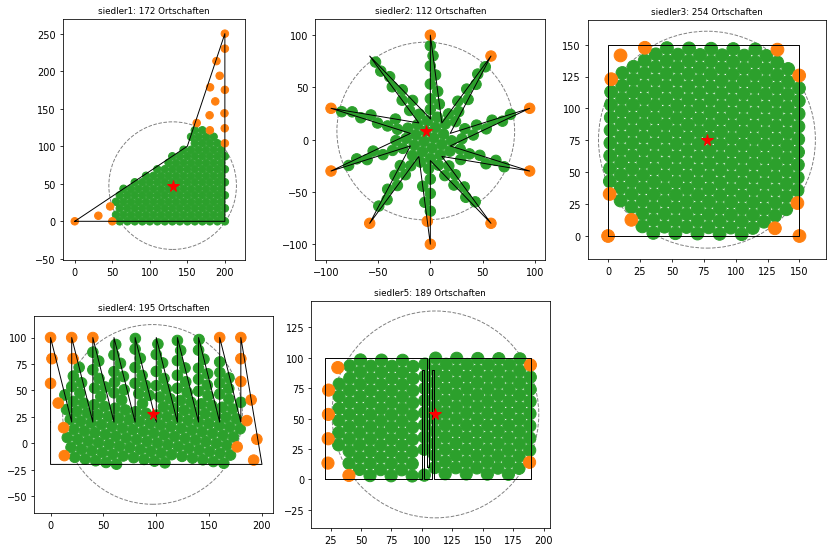

In [ ]:
import matplotlib.pyplot as plt


def zeichne(nr, name, achse):
    g, plan, regel = plan_zu(nr, name)
    polygon = gebiete[nr]
    xs = [p[0] for p in polygon] + [polygon[0][0]]
    ys = [p[1] for p in polygon] + [polygon[0][1]]
    achse.plot(xs, ys, color='black', linewidth=1)
    achse.add_patch(plt.Circle(g, R_SCHUTZ, fill=False, linestyle='--', color='gray'))
    for o in plan:
        farbe = 'tab:green' if o[2] else 'tab:orange'
        achse.add_patch(plt.Circle((o[0], o[1]), R_MIN / 2, color=farbe))
    achse.plot([g[0]], [g[1]], marker='*', color='red', markersize=12)
    achse.set_aspect('equal')
    achse.autoscale_view()
    achse.set_title('siedler' + str(nr) + ': ' + str(len(plan)) + ' Ortschaften', fontsize=9)


fig, achsen = plt.subplots(2, 3, figsize=(12, 8))
for achse, nr in zip(achsen.flatten(), range(1, 6)):
    zeichne(nr, 'Regel 1, frei', achse)
achsen.flatten()[5].axis('off')
plt.tight_layout()
plt.show()

## Schritt 7: Vergleich mit den Lösungshinweisen

Die offiziellen Hinweise geben für jedes Beispiel die Zahl der Ortschaften ihres Programms (mit genetischer Optimierung) an. Dazu
eine Schranke von 93 %, ab der eine Einsendung als „qualitativ gut“ gilt, und die obere Schranke, ab der ein Ergebnis sicher
fehlerhaft ist (`obere_schranke` oben: die Werte stimmen mit der Tabelle überein).

In [ ]:
HINWEISE = {1: (174, 171, 170, 166), 2: (117, 116, 112, 111), 3: (256, 252, 248, 244), 4: (201, 198, 194, 191),
            5: (200, 193, 194, 190)}

print('Beispiel      ' + '  '.join([name.ljust(15) for name, fest, regel in FAELLE]))
for nr in range(1, 6):
    zeile = ('siedler' + str(nr)).ljust(14)
    for k in range(4):
        wir = ergebnis[(nr, FAELLE[k][0])][0]
        hinweis = HINWEISE[nr][k]
        zeile += (str(wir) + ' von ' + str(hinweis) + ' (' + str(round(100 * wir / hinweis)) + ' %)').ljust(17)
    print(zeile)
unter = []
for nr in range(1, 6):
    for k in range(4):
        wir = ergebnis[(nr, FAELLE[k][0])][0]
        if wir < 0.93 * HINWEISE[nr][k]:
            unter.append((nr, FAELLE[k][0]))
print('Unter 93 %:', unter)

Beispiel      Regel 1, frei    Regel 1, fest    Regel 2, frei    Regel 2, fest  
siedler1      172 von 174 (99 %)164 von 171 (96 %)169 von 170 (99 %)162 von 166 (98 %)
siedler2      112 von 117 (96 %)113 von 116 (97 %)107 von 112 (96 %)108 von 111 (97 %)
siedler3      254 von 256 (99 %)249 von 252 (99 %)245 von 248 (99 %)239 von 244 (98 %)
siedler4      195 von 201 (97 %)192 von 198 (97 %)189 von 194 (97 %)188 von 191 (98 %)
siedler5      189 von 200 (94 %)192 von 193 (99 %)187 von 194 (96 %)186 von 190 (98 %)
Unter 93 %: []


Ehrlich gesagt: Wir erreichen die Zahlen der Lösungshinweise **nicht ganz**. In keinem der 20 Fälle sind wir besser, bei `siedler3`
liegen wir mit 98 bis 99 % dicht dran (bei `siedler1` bis auf einen Fall auch), am schwächsten ist `siedler5` mit Regel 1 und freiem Gesundheitszentrum
(94 %). Alle Werte liegen aber über der 93-%-Schranke für „qualitativ gute“ Lösungen. Die Hinweise haben den Startwert mit einem
genetischen Algorithmus und sehr vielen Läufen gesucht, wir mit nur 140 Läufen je Feld. Mit einem größeren `zufall_n` und mehr
`schritte` käme man näher an die Zahlen der Hinweise, braucht aber entsprechend länger.

## Schritt 8: Was bringen die Bevorzugungen?

Wir schalten die Bevorzugungen einzeln ab und lassen sonst alles gleich (Regel 1, freies Gesundheitszentrum, dieselbe Suche).

In [ ]:
for nr in (1, 2, 4):
    mit_allem = ergebnis[(nr, 'Regel 1, frei')][0]
    ohne_ecken = suche(gebiete[nr], False, 1, ecken=False)[0]
    ohne_seite = suche(gebiete[nr], False, 1, seite=False)[0]
    print('siedler' + str(nr) + ': mit allem', mit_allem, ', ohne Ecken', ohne_ecken, ', ohne die Regel „andere Seite zuerst“', ohne_seite)

siedler1: mit allem 172 , ohne Ecken 170 , ohne die Regel „andere Seite zuerst“ 172
siedler2: mit allem 112 , ohne Ecken 112 , ohne die Regel „andere Seite zuerst“ 103
siedler4: mit allem 195 , ohne Ecken 195 , ohne die Regel „andere Seite zuerst“ 192


Die Regel „andere Seite zuerst“ bringt bei `siedler2` (viele enge Spitzen) 9 Ortschaften mehr (112 statt 103) und bei `siedler4`
drei mehr, bei `siedler1` (ein einfaches Viereck mit einer Einbuchtung) nichts. Die Ecken des Polygons helfen nur bei
`siedler1` (zwei mehr, 172 statt 170). Das stimmt zu den Angaben der Hinweise, dass die Ecken nur bei manchen Gebieten nötig sind.

## Zum Schluss: MiniZinc?

Wir haben MiniZinc für diese Aufgabe nicht benutzt. Die Unbekannten sind **Koordinaten** (reelle Zahlen), und die Bedingungen sind
Abstände (`wurzel((x-x')² + (y-y')²) ≥ 10`). Die Solver aus den Arbeitsblättern (Gecode, Chuffed, CP-SAT) rechnen mit ganzen
Zahlen. Man könnte die Koordinaten auf ein Gitter legen, dann wird aus der Aufgabe die Frage nach der größten Menge von Gitterpunkten,
die paarweise weit genug auseinanderliegen (ein „unabhängige Menge“-Problem). Das wäre aber nur eine grobe Näherung, die dichte
Anordnungen (Sechseckmuster, Randpunkte, Ecken) nicht trifft. Außerdem hat bereits ein Gitter von 1 km Feinheit etwa 16 000 Punkte
(`siedler1`) und die Abstandsbedingungen zwischen allen nahen Paaren machen das Modell sehr groß. Das Greedy-Verfahren mit
Kreisschnittpunkten nutzt die Geometrie des Problems viel besser.

## Für Neugierige

- Die Lösungshinweise suchen die Startwerte mit einem **genetischen Algorithmus** (eine Gruppe von Startwerten, die besten bleiben,
  neue entstehen durch Mischen und kleine zufällige Änderungen). Das ist mit unserer Suche verwandt, nur mit einer ganzen Gruppe
  statt eines einzigen Startwerts.
- Mit einem **Quadtree** statt der Liste kämen die Nachbarn noch schneller. Unser Gitter aus 20-km-Quadraten tut dasselbe in
  einfacher Form.
- Die obere Schranke ist großzügig: Am Rand und an Ecken lässt sich das Sechseckmuster nie ganz ausnutzen.